In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from urllib.request import urlopen

In [2]:
# Windows용 한글 폰트 오류 해결
from matplotlib import font_manager, rc
from pathlib import Path
font_path = "C:/Windows/Fonts/malgun.ttf"
if not Path(font_path).is_file():
    font_path = next(
        (path for path in (
            "/System/Library/Fonts/Supplemental/AppleGothic.ttf",
            "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc",
            "/usr/share/fonts/truetype/nanum/NanumGothic.ttf",
        ) if Path(path).is_file()),
        font_path,
    )
font_name = font_manager.FontProperties(fname = font_path).get_name()
rc("font", family = font_name)

# 데이터 수집

In [3]:
url = "https://youtube-rank.com/board/bbs/board.php?bo_table=youtube"

page = urlopen(url)

soup = BeautifulSoup(page, "lxml")

In [4]:
soup.select("p.category")[0].string.strip()

'[음악/댄스/가수]'

In [5]:
soup.select("td.subject > a")[0].string.strip()

'BLACKPINK'

In [6]:
soup.select("td.subscriber_cnt")[0].string

'9610만'

In [7]:
soup.select("td.view_cnt")[0].string

'382억6552만'

In [8]:
soup.select("td.video_cnt")[0].string

'605개'

In [9]:
soup.select("td.hit > strong")[0].string

'48,444'

In [10]:
# 10페이지까지 데이터 수집
result_dict = {"cate" : [],
               "title" : [],
               "subscriber" : [],
               "view" : [],
               "video" : [],
               "hit" : []}

base_url = "https://youtube-rank.com/board/bbs/board.php?bo_table=youtube&page="

for page_num in range(1, 11):
    page = urlopen(base_url + str(page_num))
    soup = BeautifulSoup(page, "lxml")
    result_dict["cate"] += soup.select("p.category")
    result_dict["title"] += soup.select("td.subject > a")
    result_dict["subscriber"] += soup.select("td.subscriber_cnt")
    result_dict["view"] += soup.select("td.view_cnt")
    result_dict["video"] += soup.select("td.video_cnt")
    result_dict["hit"] += soup.select("td.hit > strong")

In [11]:
print(len(result_dict["cate"]))
print(len(result_dict["title"]))
print(len(result_dict["subscriber"]))
print(len(result_dict["view"]))
print(len(result_dict["video"]))
print(len(result_dict["hit"]))

1000
1000
1000
1000
1000
1000


In [17]:
result_dict["cate"] = [i.string.strip() for i in result_dict["cate"]]
result_dict["title"] = [i.string.strip() for i in result_dict["title"]]
result_dict["subscriber"] = [i.string.strip() for i in result_dict["subscriber"]]
result_dict["view"] = [i.string.strip() for i in result_dict["view"]]
result_dict["video"] = [i.string.strip() for i in result_dict["video"]]
result_dict["hit"] = [i.string.strip() for i in result_dict["hit"]]

In [18]:
df = pd.DataFrame(result_dict)

In [19]:
df.head()

,cate,title,subscriber,view,video,hit
0,[음악/댄스/가수],BLACKPINK,9610만,382억6552만,605개,"48,444"
1,[BJ/인물/연예인],김프로KIMPRO,9350만,585억6779만,"3,052개","17,386"
2,[음악/댄스/가수],BANGTANTV,7990만,246억5686만,"2,741개","22,422"
3,[음악/댄스/가수],HYBE LABELS,7670만,384억6479만,"2,354개","23,016"
4,[미분류],Mark Rober,6550만,107억1732만,201개,"7,664"


In [20]:
# 데이터프레임을 엑셀로 저장
df.to_excel("youtube_rank.xlsx", index = False)

# 유튜브 랭킹 데이터 분석

In [22]:
df.head()

,cate,title,subscriber,view,video,hit
0,[음악/댄스/가수],BLACKPINK,9610만,382억6552만,605개,"48,444"
1,[BJ/인물/연예인],김프로KIMPRO,9350만,585억6779만,"3,052개","17,386"
2,[음악/댄스/가수],BANGTANTV,7990만,246억5686만,"2,741개","22,422"
3,[음악/댄스/가수],HYBE LABELS,7670만,384억6479만,"2,354개","23,016"
4,[미분류],Mark Rober,6550만,107억1732만,201개,"7,664"


- subscriber 는 모든 데이터가 ~만 으로 조합된 문자열 값
    - 만 -> 0000으로 치환하여 int타입 변환

In [25]:
df["subscriber"] = df["subscriber"].str.replace("만", "0000").astype(int)

In [26]:
df.head()

,cate,title,subscriber,view,video,hit
0,[음악/댄스/가수],BLACKPINK,96100000,382억6552만,605개,"48,444"
1,[BJ/인물/연예인],김프로KIMPRO,93500000,585억6779만,"3,052개","17,386"
2,[음악/댄스/가수],BANGTANTV,79900000,246억5686만,"2,741개","22,422"
3,[음악/댄스/가수],HYBE LABELS,76700000,384억6479만,"2,354개","23,016"
4,[미분류],Mark Rober,65500000,107억1732만,201개,"7,664"


In [27]:
df.shape

(1000, 6)

In [28]:
df.dtypes

cate          object
title         object
subscriber     int32
view          object
video         object
hit           object
dtype: object

## 카테고리별 구독자 수, 채널 수 분석

In [29]:
# 카테고리별 구독자수, 채널 수
casub = df.groupby("cate")["subscriber"].agg(["sum", "count"])

In [30]:
casub

,sum,count
cate,,
[BJ/인물/연예인],247150000,57
[IT/기술/컴퓨터],11160000,6
[TV/방송],284880000,106
[게임],77500000,45
[교육/강의],31240000,18
[국내/해외/여행],11920000,8
[뉴스/정치/사회],133380000,60
[미분류],796950000,244
[스포츠/운동],20280000,9


In [31]:
# 데이터프레임 내림차순 정렬
casub = casub.sort_values("sum", ascending = False)

In [32]:
casub.head()

,sum,count
cate,,
[음악/댄스/가수],892120000,139
[미분류],796950000,244
[키즈/어린이],468380000,131
[TV/방송],284880000,106
[BJ/인물/연예인],247150000,57


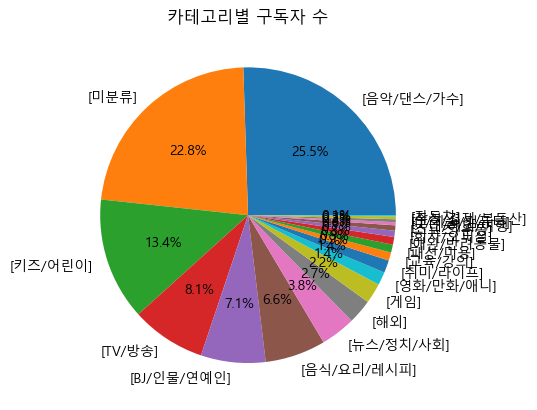

In [33]:
# 구독자 수 파이차트 시각화
plt.figure()
plt.pie(casub["sum"], labels = casub.index, autopct = "%.1f%%")
plt.title("카테고리별 구독자 수")
plt.show()

In [35]:
# 카테고리별 채널 수
casub = casub.sort_values("count", ascending = False)

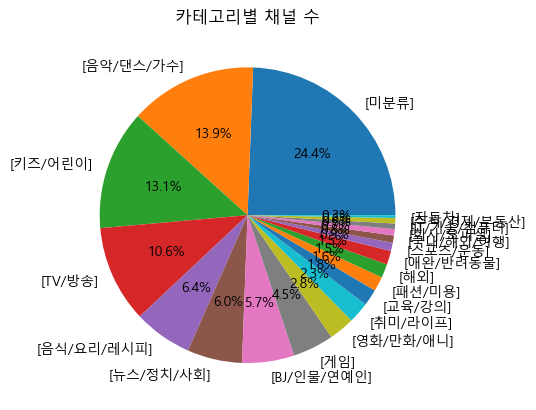

In [36]:
plt.figure()
plt.pie(casub["count"], labels = casub.index, autopct = "%.1f%%")
plt.title("카테고리별 채널 수")
plt.show()